In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob
import gseapy as gp

#sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
sc.settings.set_figure_params(dpi = 160, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')

plt.rcParams["figure.figsize"] = [6,6]

In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
from matplotlib import font_manager
font_manager.fontManager.addfont("csv/Helvetica.ttf")
print(font_manager.findfont("Helvetica"))
plt.rcParams["font.sans-serif"] = ["Helvetica"]
plt.rcParams["pdf.fonttype"] = 42

plt.rcParams['savefig.dpi'] = 300

plt.rcParams["axes.grid"] = False
plt.rcParams["pdf.fonttype"] = 42

/nfs/team205/cs42/HSC/HSC_new_to_transfer/csv/Helvetica.ttf


In [5]:
# figure directory
fig_path = 'figure/'
#fig_path = '/home/jovyan/mount/gdrive/HSC/chenqu_jhub/'
sc.settings.figdir = fig_path

# Load data

In [6]:
adata = sc.read("/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/pool_scvi_v2.h5ad")

In [7]:
adata_d18 = adata[adata.obs['HSC_days']==18]
# recalculated neighbourhood and UMAP
sc.pp.neighbors(adata_d18, use_rep = 'X_scVI', random_state=1712)
sc.tl.umap(adata_d18,random_state=1712)

In [8]:
sc.tl.leiden(adata_d18, resolution =1)

/tmp/ipykernel_2753491/2395019767.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_d18, resolution =1)


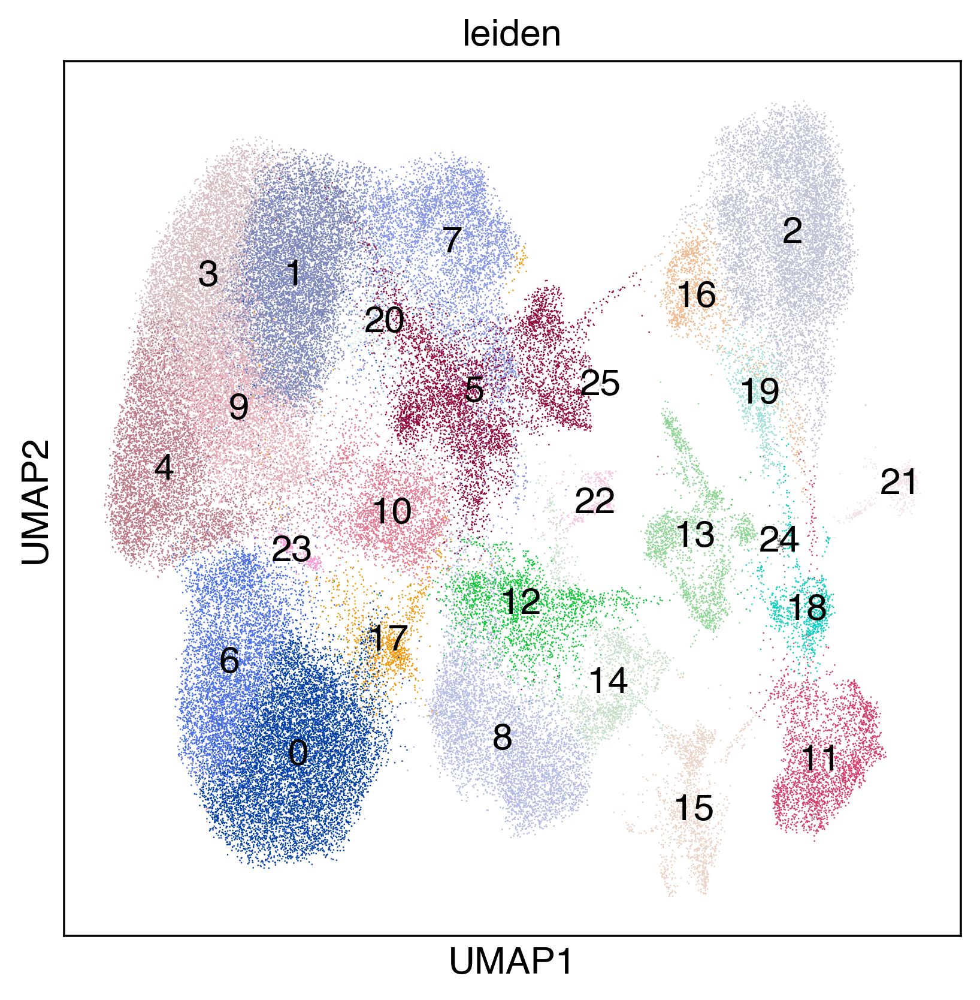

In [9]:
sc.pl.umap(adata_d18, color=['leiden'], legend_loc = 'on data', save = 'adata_d18_leiden.pdf')

# Celltypist

In [10]:
import celltypist
from celltypist import models

In [11]:
# Enabling `force_update = True` will overwrite existing (old) models.
models.download_models(force_update = True)

📜 Retrieving model list from server https://celltypist.cog.sanger.ac.uk/models/models.json
📚 Total models in list: 61
📂 Storing models in /nfs/users/nfs_c/cs42/.celltypist/data/models
💾 Downloading model [1/61]: Immune_All_Low.pkl
💾 Downloading model [2/61]: Immune_All_High.pkl
💾 Downloading model [3/61]: Adult_COVID19_PBMC.pkl
💾 Downloading model [4/61]: Adult_CynomolgusMacaque_Hippocampus.pkl
💾 Downloading model [5/61]: Adult_Human_MTG.pkl
💾 Downloading model [6/61]: Adult_Human_PancreaticIslet.pkl
💾 Downloading model [7/61]: Adult_Human_PrefrontalCortex.pkl
💾 Downloading model [8/61]: Adult_Human_Skin.pkl
💾 Downloading model [9/61]: Adult_Human_Vascular.pkl
💾 Downloading model [10/61]: Adult_Mouse_Gut.pkl
💾 Downloading model [11/61]: Adult_Mouse_OlfactoryBulb.pkl
💾 Downloading model [12/61]: Adult_Pig_Hippocampus.pkl
💾 Downloading model [13/61]: Adult_RhesusMacaque_Hippocampus.pkl
💾 Downloading model [14/61]: Adult_cHSPCs_Illumina.pkl
💾 Downloading model [15/61]: Adult_cHSPCs_Ultima

In [12]:
predictions = celltypist.annotate(adata_d18, model = 'Pan_Fetal_Human.pkl', majority_voting = True)

🔬 Input data has 84562 cells and 36601 genes
🔗 Matching reference genes in the model
🧬 7121 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 20
🗳️ Majority voting the predictions
✅ Majority voting done!


In [13]:
# Get an `AnnData` with predicted labels embedded into the cell metadata columns.
adata_d18 = predictions.to_adata()

In [14]:
neuron_prob = predictions.probability_matrix.loc[:,'NEURON']
adata_d18.obs['neuron_prob'] = neuron_prob

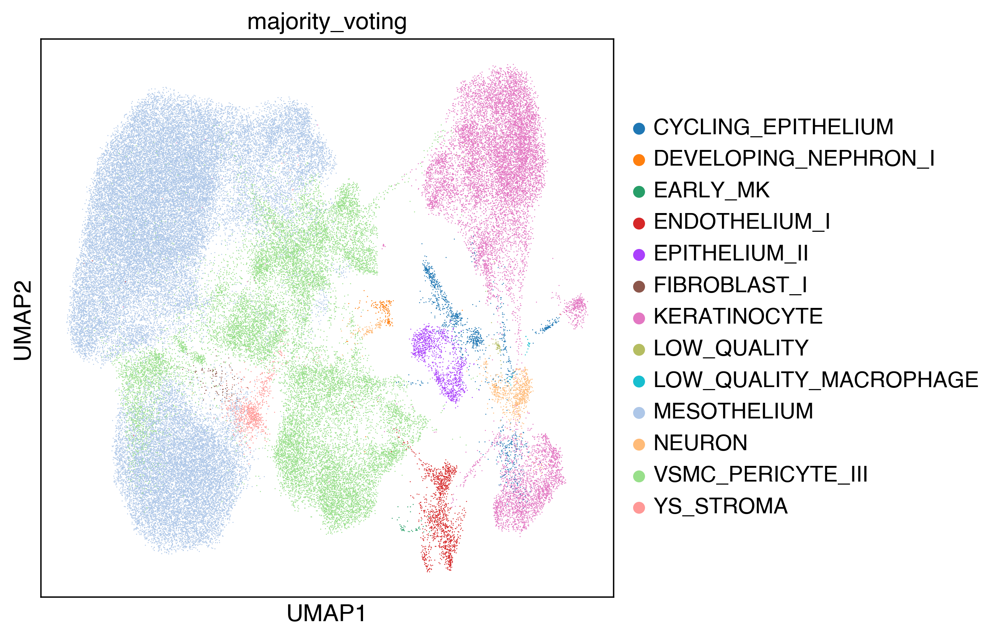

In [15]:
sc.pl.umap(adata_d18, color=['majority_voting'])

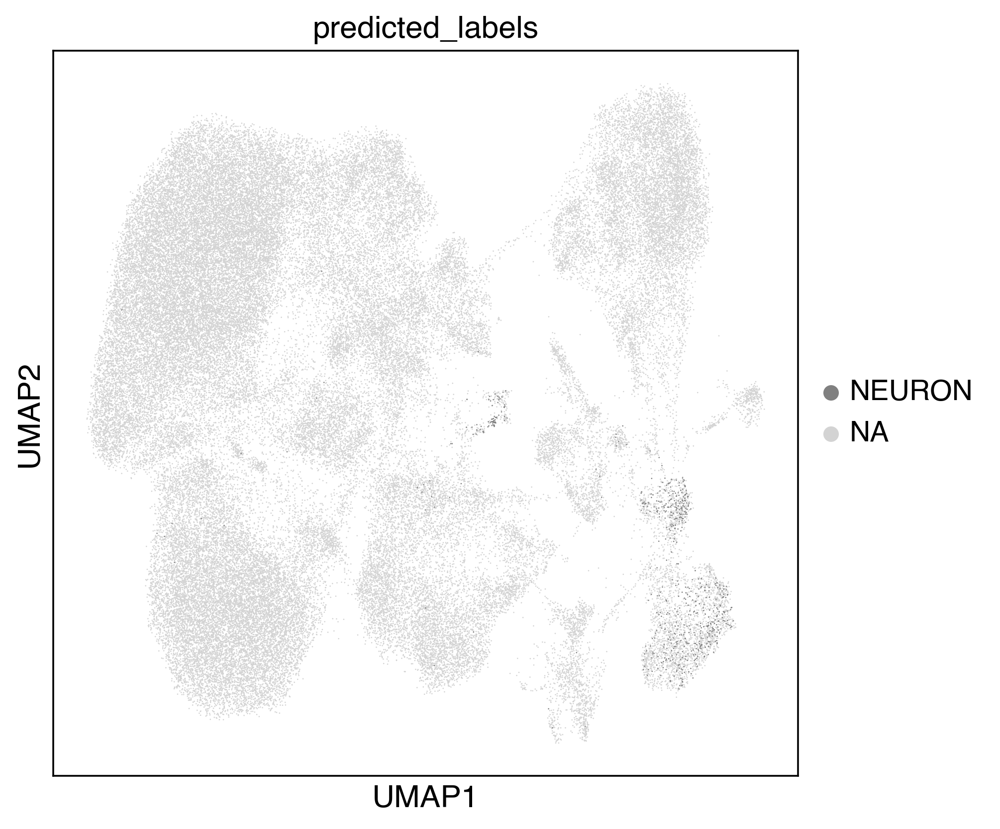

In [16]:
sc.pl.umap(adata_d18, color=['predicted_labels'], groups = ['NEURON'])

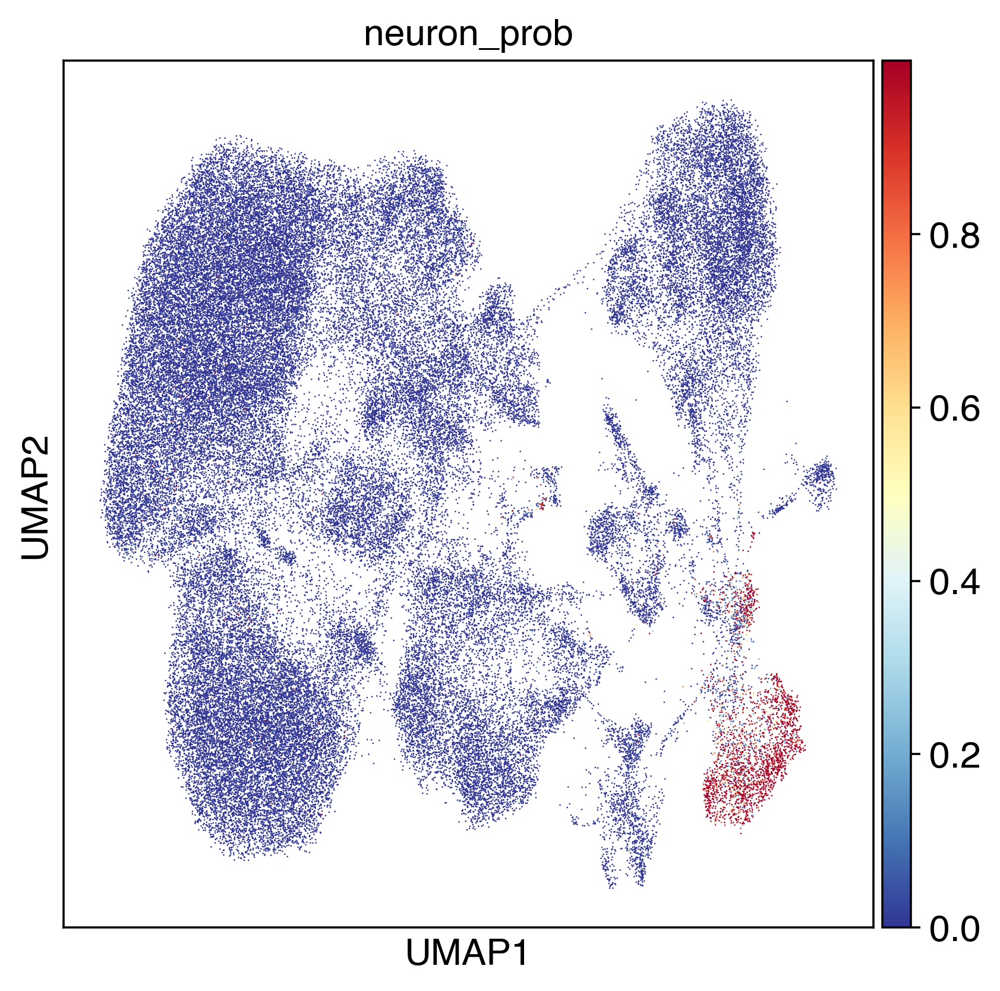

In [17]:
sc.pl.umap(adata_d18, color=['neuron_prob'])

In [18]:
adata_d18.write_h5ad('/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/pool_scvi_celltypist_v2.h5ad')

In [6]:
adata_d18 = sc.read('/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/pool_scvi_celltypist_v2.h5ad')

# SMAD7 - Cluster 22: Neuronal cells

In [41]:
# % of SMAD7 cells in leiden cluster 22
a = np.array(adata_d18.obs['TF_calling']=='SMAD7')
b = np.array(adata_d18.obs['leiden']=='22')
sum(a&b)/sum(a)*100

np.float64(84.33734939759037)

maxp pruned
cmap pruned
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 18 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'D', 'F', 'M', 'N', 'S', 'T', 'a', 'c', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'seven', 'space']
Glyph IDs:   [0, 1, 2, 3, 26, 36, 39, 41, 48, 49, 54, 55, 68, 70, 74, 76, 79, 81]
Closed glyph list over 'GSUB': 18 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'D', 'F', 'M', 'N', 'S', 'T', 'a', 'c', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'seven', 'space']
Glyph IDs:   [0, 1, 2, 3, 26, 36, 39, 41, 48, 49, 54, 55, 68, 70, 74, 76, 79, 81]
Closing glyph list over 'glyf': 18 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'D', 'F', 'M', 'N', 'S', 'T', 'a', 'c', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'seven', 'space']
Glyph IDs:   [0, 1, 2, 3, 26, 36, 39, 41, 48, 49, 54, 55, 68, 70, 74, 76, 79, 81]
Closed glyph list over 'glyf': 18 glyphs after
Glyph names

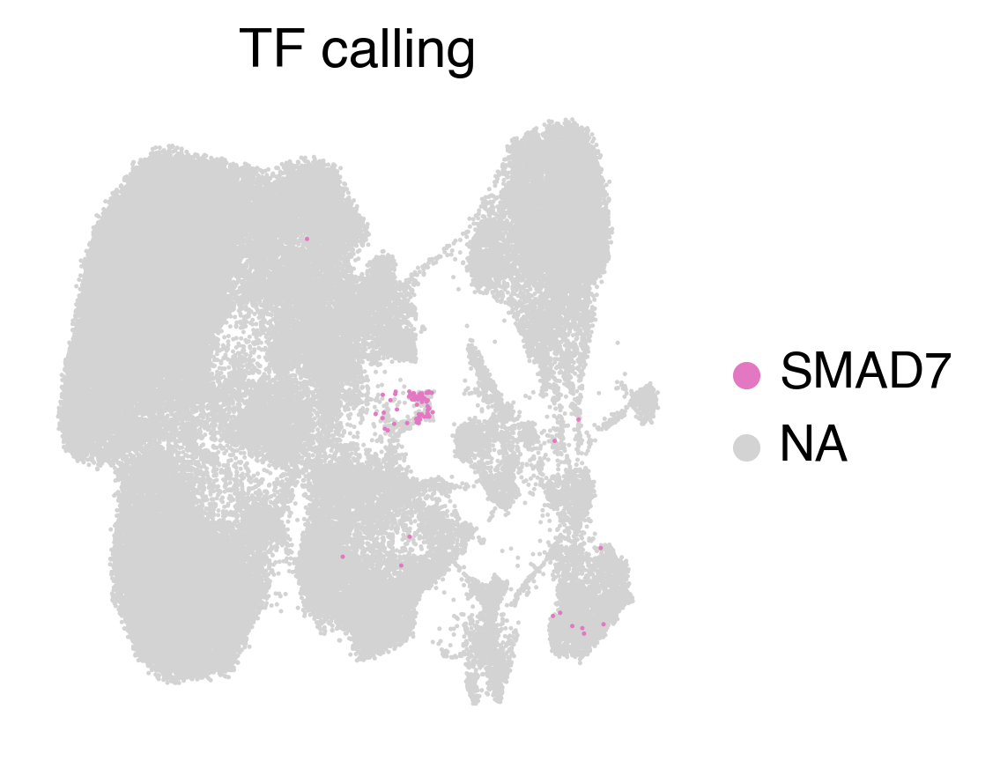

In [19]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(adata_d18, color=['TF_calling'], groups = ['SMAD7'], 
           title = 'TF calling',
           palette=["tab:pink"], 
           size = 5, frameon=False, save = 'smad7_umap.pdf')

In [20]:
c22 = adata_d18[adata_d18.obs['leiden']=='22']
# recalculated neighbourhood and UMAP
sc.pp.neighbors(c22, use_rep = 'X_scVI', random_state=1712)
sc.tl.umap(c22,random_state=1712)

In [21]:
c22.write_h5ad('/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/pool_scvi_celltypist_c22_v2.h5ad')

In [6]:
c22 = sc.read('/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/pool_scvi_celltypist_c22_v2.h5ad')

In [22]:
sc.settings.set_figure_params(dpi = 300, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')
#sc.settings.set_figure_params(dpi = 160, color_map ='RdPu')

maxp pruned
cmap pruned
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 24 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'G', 'M', 'N', 'O', 'P', 'S', 'T', 'U', 'X', 'five', 'four', 'nonmarkingreturn', 'one', 'period', 'space', 'three', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 22, 23, 24, 36, 37, 38, 39, 42, 48, 49, 50, 51, 54, 55, 56, 59]
Closed glyph list over 'GSUB': 24 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'G', 'M', 'N', 'O', 'P', 'S', 'T', 'U', 'X', 'five', 'four', 'nonmarkingreturn', 'one', 'period', 'space', 'three', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 22, 23, 24, 36, 37, 38, 39, 42, 48, 49, 50, 51, 54, 55, 56, 59]
Closing glyph list over 'glyf': 24 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'G', 'M', 'N', 'O', 'P', 'S', 'T', 'U', 'X', 'five', 'four', 'nonmarkingreturn'

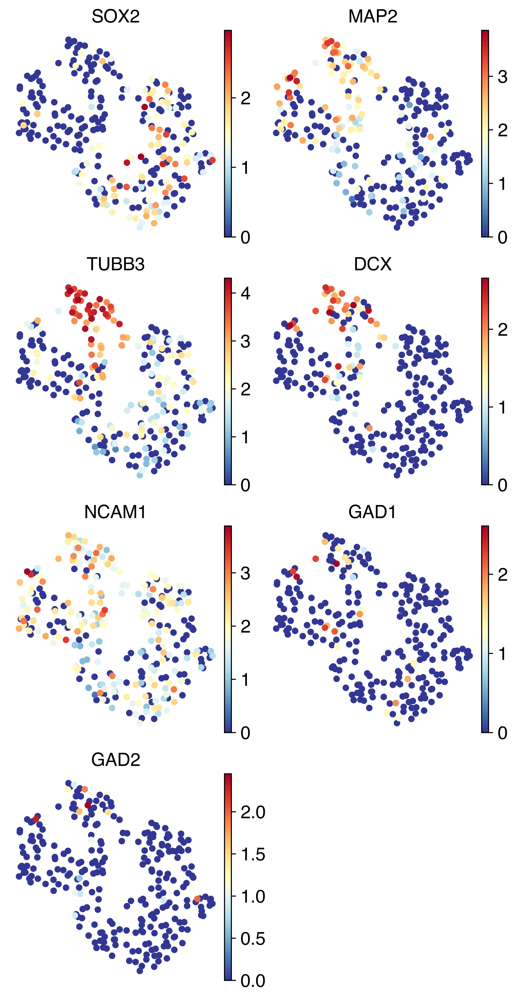

In [23]:
# combined neuronal markers
plt.rcParams["figure.figsize"] = [3,3]
genes = ['SOX2',  #Neural Ectoderm
'MAP2','TUBB3','DCX','NCAM1', # NEURON MARKERS
         'GAD1','GAD2'
]
sc.pl.umap(c22, color=genes, size=100, frameon=False, wspace = 0.1,hspace = 0.2,ncols=2, save = 'c22_neuron_markers.pdf')

maxp pruned
cmap pruned
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 15 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'C', 'M', 'N', 'O', 'S', 'X', 'nonmarkingreturn', 'one', 'space', 'three', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 19, 20, 21, 22, 36, 38, 48, 49, 50, 54, 59]
Closed glyph list over 'GSUB': 15 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'C', 'M', 'N', 'O', 'S', 'X', 'nonmarkingreturn', 'one', 'space', 'three', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 19, 20, 21, 22, 36, 38, 48, 49, 50, 54, 59]
Closing glyph list over 'glyf': 15 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'C', 'M', 'N', 'O', 'S', 'X', 'nonmarkingreturn', 'one', 'space', 'three', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 19, 20, 21, 22, 36, 38, 48, 49, 50, 54, 59]
Closed glyph list over 'glyf': 15 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'C', 'M', 'N', 'O', 'S', 'X', 'n

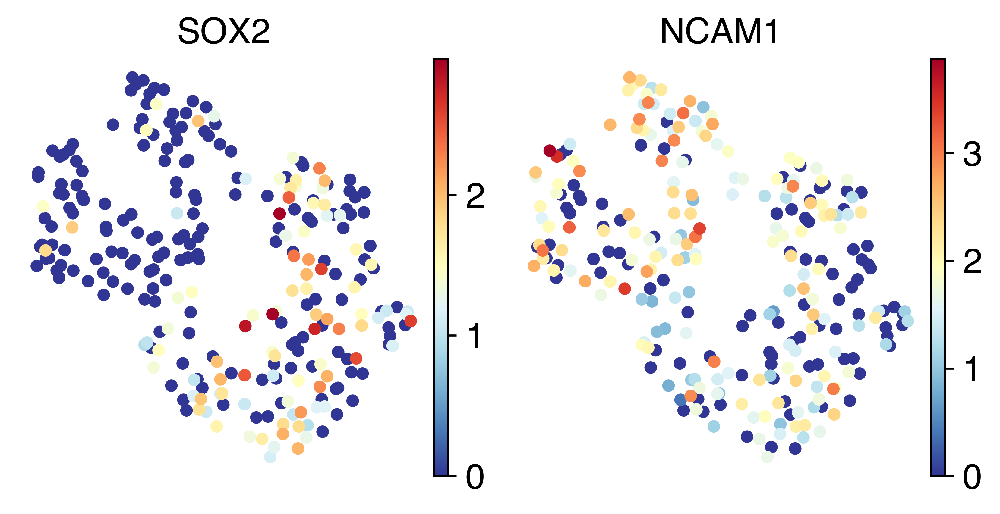

In [24]:
# combined neuronal markers
plt.rcParams["figure.figsize"] = [3,3]
genes = ['SOX2',  #Neural Ectoderm
'NCAM1'
]
sc.pl.umap(c22, color=genes, size=100, frameon=False, wspace = 0.1,hspace = 0.2,ncols=3, save = 'c22_neuron_markers_simplified1.pdf')

maxp pruned
cmap pruned
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 18 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'M', 'P', 'T', 'U', 'X', 'four', 'nonmarkingreturn', 'one', 'space', 'three', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 19, 20, 21, 22, 23, 36, 37, 38, 39, 48, 51, 55, 56, 59]
Closed glyph list over 'GSUB': 18 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'M', 'P', 'T', 'U', 'X', 'four', 'nonmarkingreturn', 'one', 'space', 'three', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 19, 20, 21, 22, 23, 36, 37, 38, 39, 48, 51, 55, 56, 59]
Closing glyph list over 'glyf': 18 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'M', 'P', 'T', 'U', 'X', 'four', 'nonmarkingreturn', 'one', 'space', 'three', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 19, 20, 21, 22, 23, 36, 37, 38, 39, 48, 51, 55, 56, 59]
Closed glyph list over 'glyf

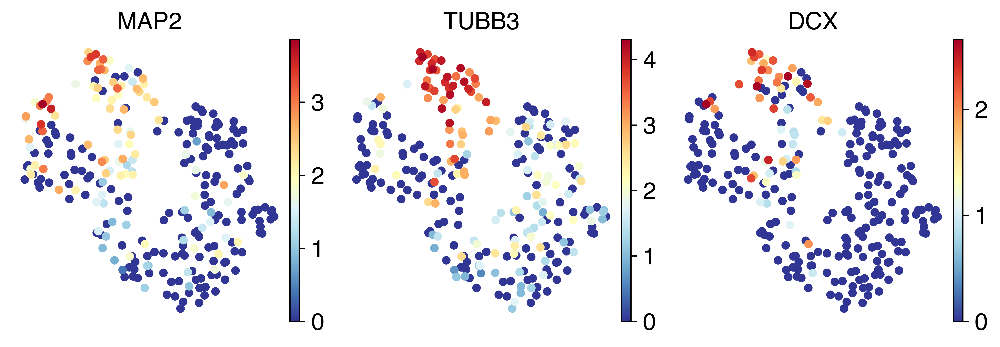

In [25]:
# combined neuronal markers
plt.rcParams["figure.figsize"] = [3,3]
genes = [  #Neural Ectoderm
'MAP2','TUBB3','DCX'
]
sc.pl.umap(c22, color=genes, size=100, frameon=False, wspace = 0.1,hspace = 0.2,ncols=3, save = 'c22_neuron_markers_simplified2.pdf')

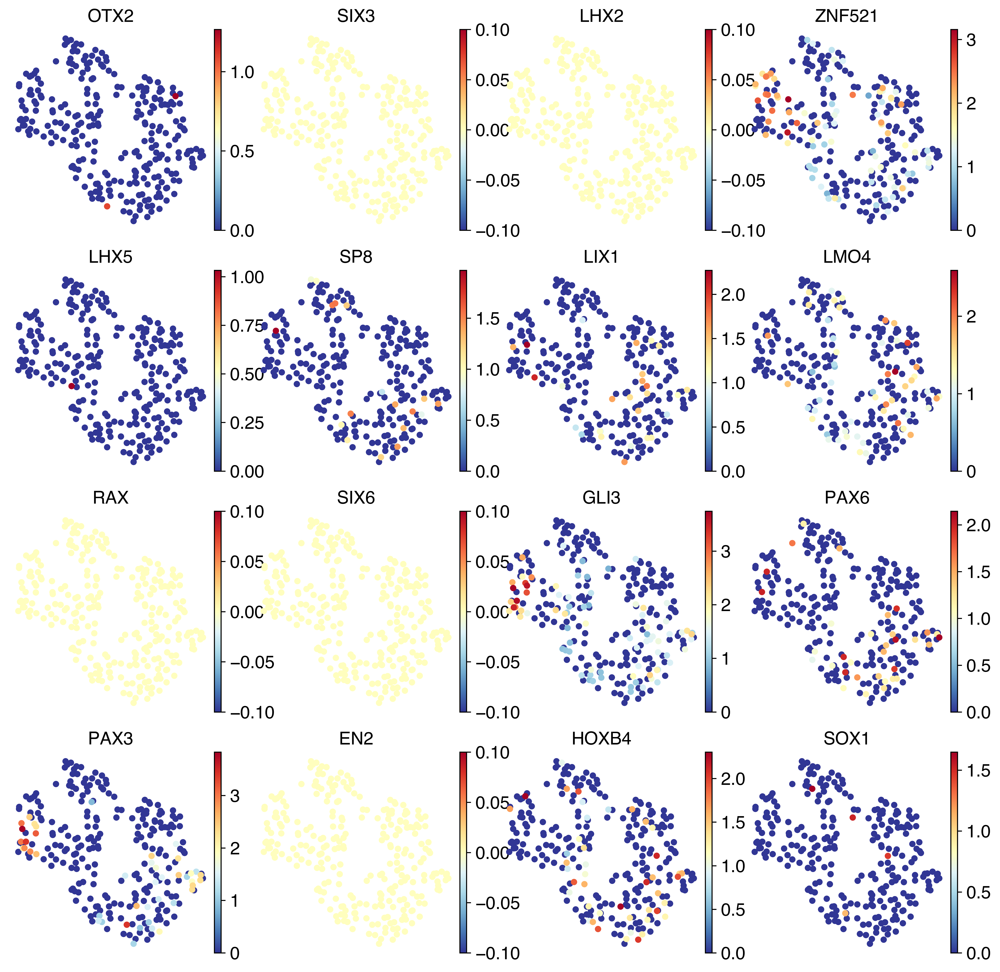

In [26]:
genes = ['OTX2','SIX3','LHX2','ZNF521','LHX5','SP8','LIX1','LMO4','RAX','SIX6','GLI3', #anterior
'PAX6','PAX3',#dorsal/ventral within forebrain
'EN2',#midbrain
'HOXB4',#hindbrain/spinal cord 
         'SOX1',
]
sc.pl.umap(c22, color=genes, size=100, frameon=False, wspace = 0.1,hspace = 0.2,ncols=4, save = 'c22_neuron_markers_more.png')# genes from https://pmc.ncbi.nlm.nih.gov/articles/PMC4103884/#F4 - SMAD7 in ESC

In [27]:
sc.settings.set_figure_params(dpi = 160, color_map ='RdPu')

maxp pruned
cmap pruned
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 29 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'M', 'P', 'U', 'a', 'b', 'c', 'd', 'e', 'eight', 'four', 'i', 'l', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'period', 'r', 'six', 'space', 't', 'two', 'u', 'y', 'zero']
Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 23, 25, 27, 36, 48, 51, 56, 68, 69, 70, 71, 72, 76, 79, 81, 82, 83, 85, 87, 88, 92]
Closed glyph list over 'GSUB': 29 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'M', 'P', 'U', 'a', 'b', 'c', 'd', 'e', 'eight', 'four', 'i', 'l', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'period', 'r', 'six', 'space', 't', 'two', 'u', 'y', 'zero']
Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 23, 25, 27, 36, 48, 51, 56, 68, 69, 70, 71, 72, 76, 79, 81, 82, 83, 85, 87, 88, 92]
Closing glyph list over 'glyf': 29 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'M', '

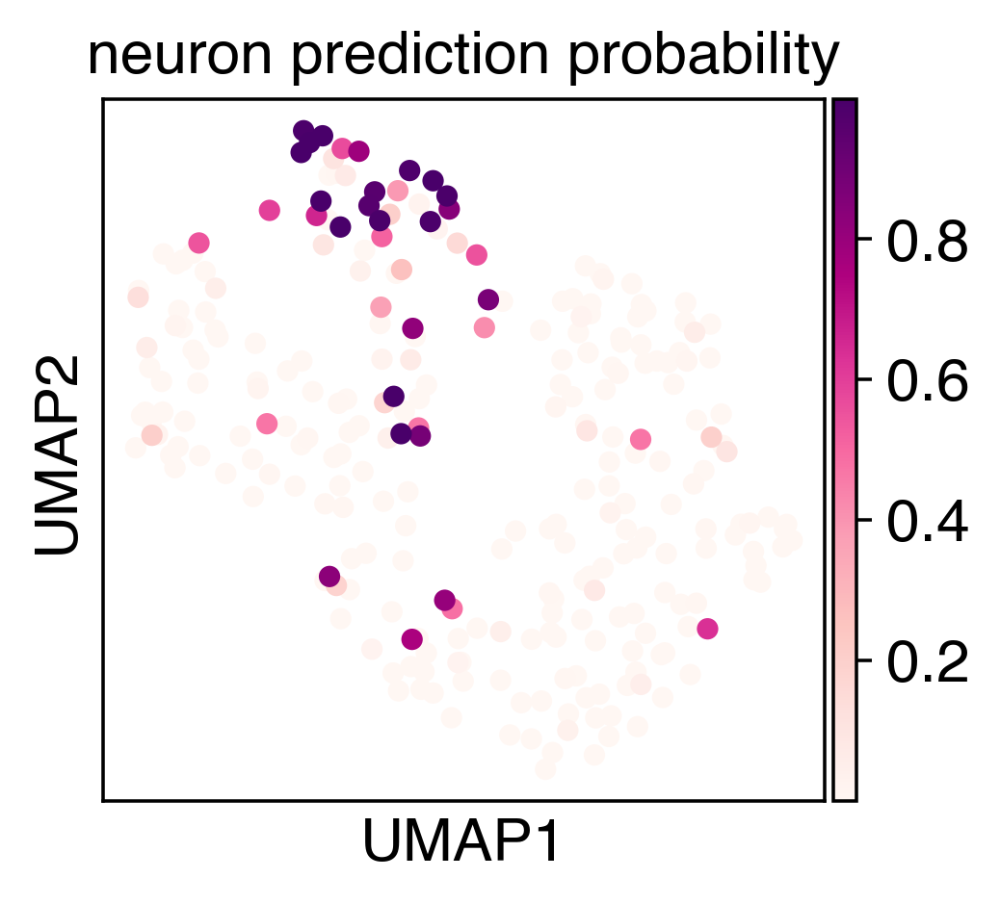

In [40]:
plt.rcParams["figure.figsize"] = [3.3,3]
sc.pl.umap(c22, color=['neuron_prob'], size=100, title = 'neuron prediction probability', save = 'c22_celltypist.pdf')

maxp pruned
cmap pruned
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 26 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'D', 'F', 'H', 'I', 'L', 'M', 'N', 'P', 'S', 'T', 'U', 'a', 'c', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'one', 'seven', 'space', 'two', 'underscore']
Glyph IDs:   [0, 1, 2, 3, 20, 21, 26, 36, 39, 41, 43, 44, 47, 48, 49, 51, 54, 55, 56, 66, 68, 70, 74, 76, 79, 81]
Closed glyph list over 'GSUB': 26 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'D', 'F', 'H', 'I', 'L', 'M', 'N', 'P', 'S', 'T', 'U', 'a', 'c', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'one', 'seven', 'space', 'two', 'underscore']
Glyph IDs:   [0, 1, 2, 3, 20, 21, 26, 36, 39, 41, 43, 44, 47, 48, 49, 51, 54, 55, 56, 66, 68, 70, 74, 76, 79, 81]
Closing glyph list over 'glyf': 26 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'D', 'F', 'H', 'I', 'L', 'M', 'N', 'P', 'S', 'T', 'U', 'a', 'c', 'g'

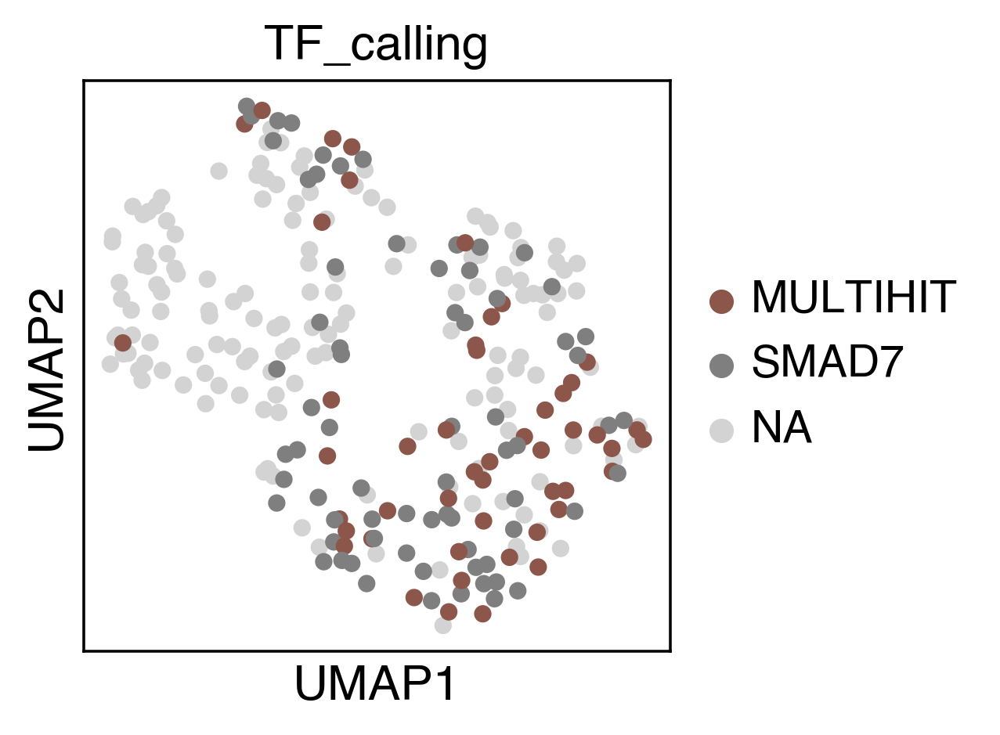

In [35]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(c22, color=['TF_calling'], groups = ['SMAD7','MULTIHIT'], size = 100, 
           palette = 'tab10',save='c22_smad7.pdf')

In [30]:
Counter(adata_d18[adata_d18.obs['leiden']=='22'].obs['TF_calling'])

Counter({nan: 132,
         'SMAD7': 70,
         'MULTIHIT': 49,
         'EGR4': 6,
         'ONECUT1': 3,
         'ESRRB': 1,
         'ETV6': 1,
         'EGR2': 1,
         'GCM2': 1,
         'TRIM38': 1,
         'KLF1': 1,
         'ZNF248': 1,
         'SOX1': 1})

In [31]:
Counter(adata_d18[adata_d18.obs['leiden']=='22'].obs['antibody_calling'])

Counter({nan: 132,
         'MULTIHIT-GGTCTCCATACG-602': 27,
         'SMAD7-AAAGTTAACGCG-2564': 25,
         'MULTIHIT-ACCTGCCGCTTC-2209': 22,
         'SMAD7-CGAGAATGCTAG-1002': 18,
         'SMAD7-AACACGTTACCC-956': 14,
         'SMAD7-TTTATGCATGAT-3090': 5,
         'SMAD7-TTAGTTCATTAT-350': 5,
         'EGR4-GCGCCAATTAAT-744': 4,
         'ONECUT1-ATGGCTTGGCCG-802': 2,
         'EGR4-TCTAGTAGAATG-814': 2,
         'SMAD7-CCGGCATAAACT-629': 2,
         'ESRRB-AAATGAGTGTCG-1060': 1,
         'ETV6-CGATGTACACCG-558': 1,
         'EGR2-CAGCACGGCCCA-776': 1,
         'GCM2-ACTGACGCCTTA-1400': 1,
         'TRIM38-TGTGTTGACCTT-1241': 1,
         'KLF1-GATCCTTTTCCG-79': 1,
         'ONECUT1-ACTGTACCGAAA-192': 1,
         'SMAD7-CAAAGAGACAGC-402': 1,
         'ZNF248-TGCACCTGAAAC-125': 1,
         'SOX1-CCCAGAATCCAA-2381': 1})

Look for MULTIHIT in feature_ref_guideseq_v2_multihit.csv
- 'MULTIHIT-GGTCTCCATACG-602': 27
    - reverse complement: CGTATGGAGACC
    - 480	CGTATGGAGACC	SMAD7
    - 122	CGTATGGAGACC	BCL11A
    - so more likely SMAD7 here 
- 'MULTIHIT-ACCTGCCGCTTC-2209': 22,
    - reverse complement:GAAGCGGCAGGT
    - 2194	GAAGCGGCAGGT	SMAD7
    - 15	GAAGCGGCAGGT	TGIF2LX
    - so more likely SMAD7 here 

In [32]:
c22.obs['TF_calling_update'] = c22.obs['TF_calling']
c22.obs.loc[c22.obs['antibody_calling'].isin(['MULTIHIT-GGTCTCCATACG-602','MULTIHIT-ACCTGCCGCTTC-2209']),'TF_calling_update'] = 'SMAD7'

maxp pruned
cmap pruned
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 18 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'D', 'F', 'M', 'N', 'S', 'T', 'a', 'c', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'seven', 'space']
Glyph IDs:   [0, 1, 2, 3, 26, 36, 39, 41, 48, 49, 54, 55, 68, 70, 74, 76, 79, 81]
Closed glyph list over 'GSUB': 18 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'D', 'F', 'M', 'N', 'S', 'T', 'a', 'c', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'seven', 'space']
Glyph IDs:   [0, 1, 2, 3, 26, 36, 39, 41, 48, 49, 54, 55, 68, 70, 74, 76, 79, 81]
Closing glyph list over 'glyf': 18 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'D', 'F', 'M', 'N', 'S', 'T', 'a', 'c', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'seven', 'space']
Glyph IDs:   [0, 1, 2, 3, 26, 36, 39, 41, 48, 49, 54, 55, 68, 70, 74, 76, 79, 81]
Closed glyph list over 'glyf': 18 glyphs after
Glyph names

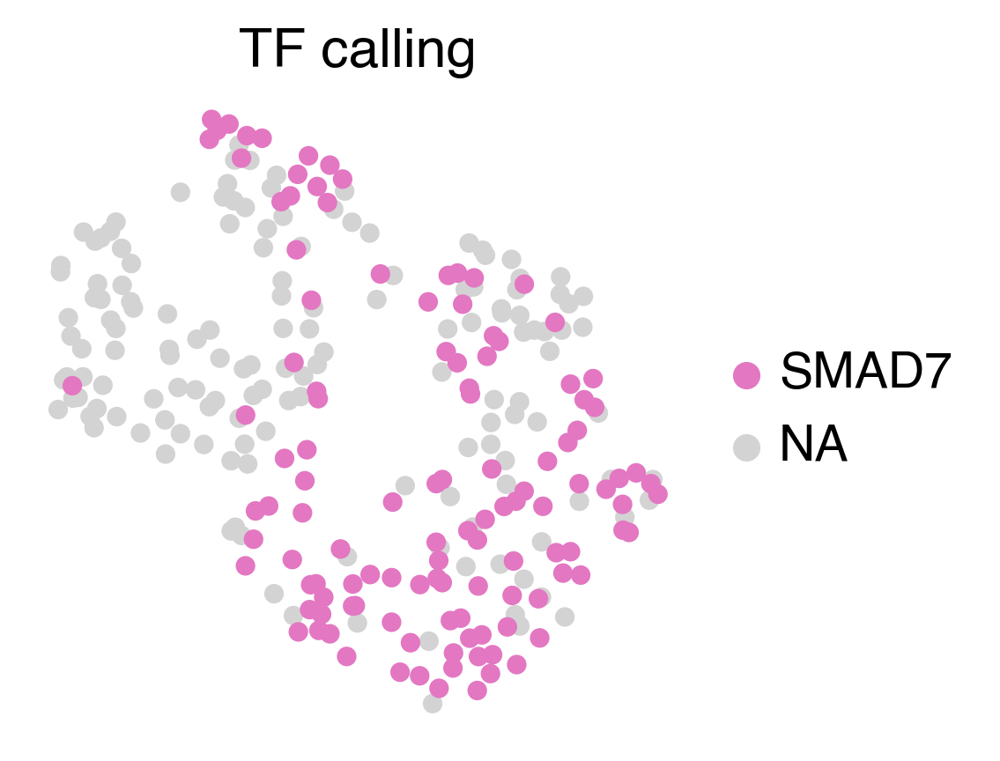

In [33]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(c22, color=['TF_calling_update'], groups=['SMAD7'], 
           palette=["tab:pink"], size=100, title = 'TF calling', 
           frameon=False,
           save = 'c22_tf.pdf')

Fisher exact test to look at enrichment

In [386]:
adata_d0 = adata[adata.obs['HSC_days']==0]

In [388]:
from scipy.stats import fisher_exact
counter_d18 = Counter(c22.obs['TF_calling_update'])
counter_d0 = Counter(adata_d0.obs['TF_calling'])

for tf in ['SMAD7']:
    
    d18_tf = counter_d18[tf]
    d18_tot = c22.shape[0]

    
    d0_tf = counter_d0[tf]
    d0_tot = adata_d0.shape[0]
    
    table = np.array([[d0_tf, d0_tot-d0_tf], [d18_tf, d18_tot-d18_tf]])

    res = fisher_exact(table, alternative='two-sided')
    print(tf, res.pvalue)

SMAD7 1.7583149762983754e-213


In [180]:
# fisher exact test of d18 specific cluster vs rest of d18
from scipy.stats import fisher_exact
counter_d18 = Counter(c22.obs['TF_calling_update'])
counter_d18_rest = Counter(adata_d18.obs.loc[~adata_d18.obs_names.isin(c22.obs_names),'TF_calling_update'])

for tf in ['SMAD7']:
    
    d18_tf = counter_d18[tf]
    d18_tot = c22.shape[0]

    
    ctl_tf = counter_d18_rest[tf]
    ctl_tot = adata_d18[~adata_d18.obs_names.isin(c22.obs_names)].shape[0]
    
    table = np.array([[ctl_tf, ctl_tot-ctl_tf], [d18_tf, d18_tot-d18_tf]])

    res = fisher_exact(table, alternative='two-sided')
    print(tf, res.pvalue)

SMAD7 2.2336918673248948e-302


# NR4A3

maxp pruned
cmap pruned
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 17 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'F', 'N', 'R', 'T', 'a', 'c', 'four', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'space', 'three']
Glyph IDs:   [0, 1, 2, 3, 22, 23, 36, 41, 49, 53, 55, 68, 70, 74, 76, 79, 81]
Closed glyph list over 'GSUB': 17 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'F', 'N', 'R', 'T', 'a', 'c', 'four', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'space', 'three']
Glyph IDs:   [0, 1, 2, 3, 22, 23, 36, 41, 49, 53, 55, 68, 70, 74, 76, 79, 81]
Closing glyph list over 'glyf': 17 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'F', 'N', 'R', 'T', 'a', 'c', 'four', 'g', 'i', 'l', 'n', 'nonmarkingreturn', 'space', 'three']
Glyph IDs:   [0, 1, 2, 3, 22, 23, 36, 41, 49, 53, 55, 68, 70, 74, 76, 79, 81]
Closed glyph list over 'glyf': 17 glyphs after
Glyph names: ['.notdef', '.nu

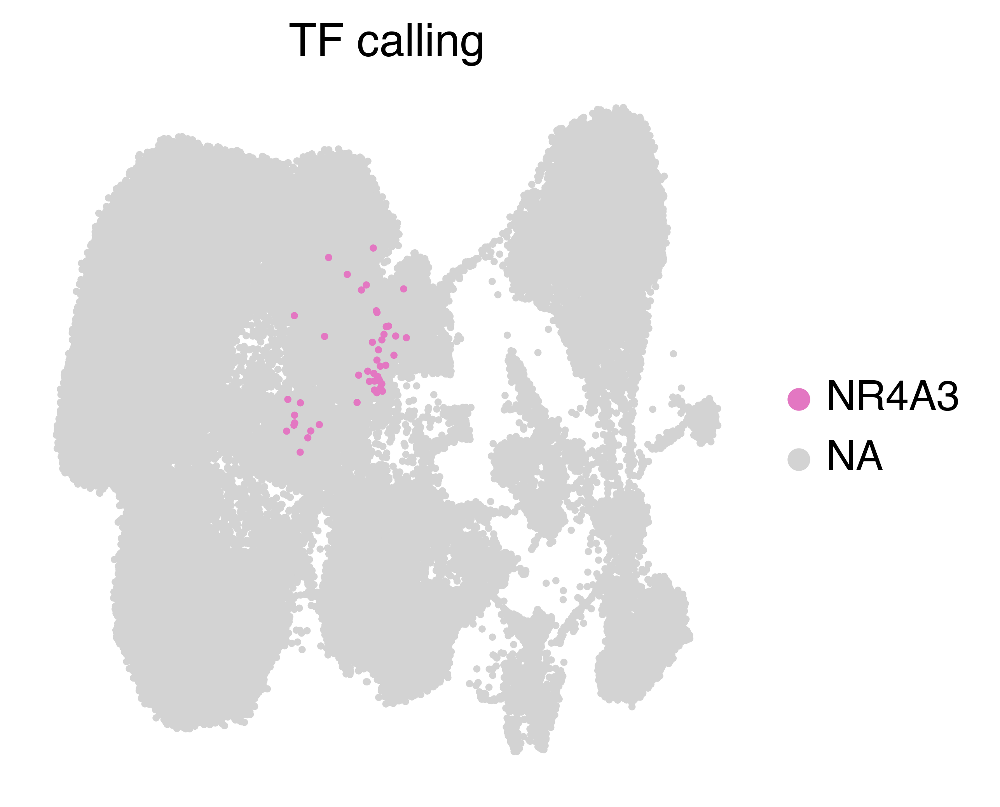

In [60]:
sc.pl.umap(adata_d18, color=['TF_calling'], frameon=False, groups = ['NR4A3'],
           title = 'TF calling', size=20,
          save='adata_d18_nr4a3.pdf')

In [43]:
nr4a3 = adata_d18[adata_d18.obs['TF_calling']=='NR4A3']

In [45]:
sc.settings.set_figure_params(dpi = 300, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')

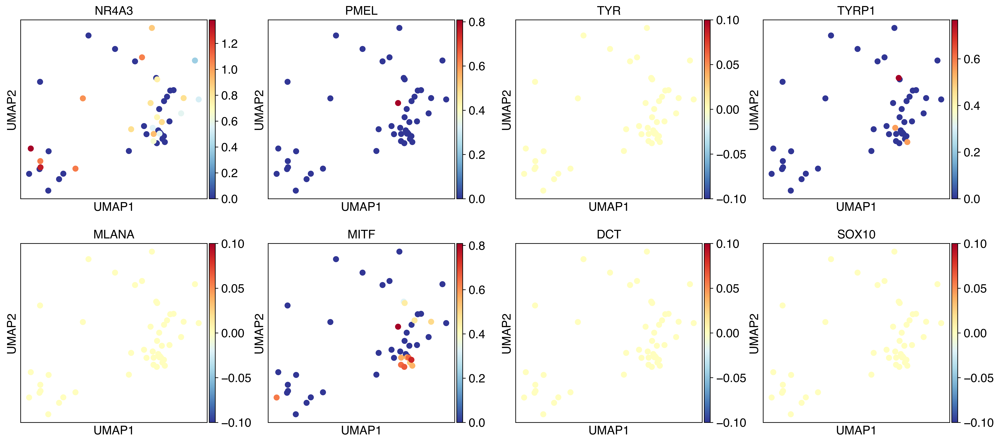

In [48]:
sc.pl.umap(nr4a3, 
           size =200, color=['NR4A3','PMEL','TYR','TYRP1','MLANA','MITF','DCT','SOX10'])

maxp pruned
cmap pruned
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 20 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'F', 'I', 'M', 'P', 'R', 'T', 'U', 'Y', 'eight', 'four', 'nonmarkingreturn', 'one', 'period', 'six', 'space', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 23, 25, 27, 36, 41, 44, 48, 51, 53, 55, 56, 60]
Closed glyph list over 'GSUB': 20 glyphs after
Glyph names: ['.notdef', '.null', 'A', 'F', 'I', 'M', 'P', 'R', 'T', 'U', 'Y', 'eight', 'four', 'nonmarkingreturn', 'one', 'period', 'six', 'space', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 23, 25, 27, 36, 41, 44, 48, 51, 53, 55, 56, 60]
Closing glyph list over 'glyf': 20 glyphs before
Glyph names: ['.notdef', '.null', 'A', 'F', 'I', 'M', 'P', 'R', 'T', 'U', 'Y', 'eight', 'four', 'nonmarkingreturn', 'one', 'period', 'six', 'space', 'two', 'zero']
Glyph IDs:   [0, 1, 2, 3, 17, 19, 20, 21, 2

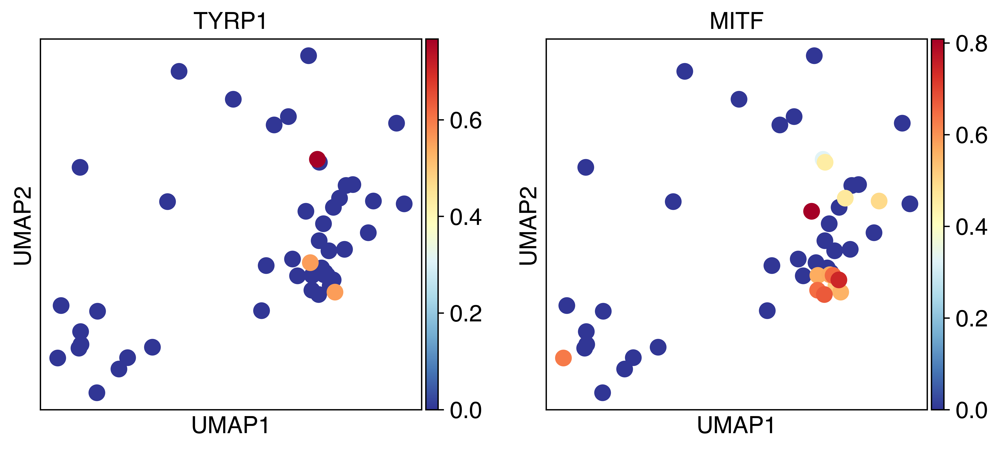

In [64]:
sc.pl.umap(nr4a3, 
           size =400, color=['TYRP1','MITF'],
          save='d18_nr4a3_melanocyte_markers.pdf')